# MoLA Routing Analysis - 96 languages

Loads routing data from `outputs/routing_analysis/...` and creates a LOLA-style family heatmap followed by a t-SNE/PCA view.


In [1]:
from pathlib import Path
import csv
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

RUN_ID = "mola_tr64_e32_k4"
APPROACH_NAME = "MoLA"
ROUTING_ROOT = Path("outputs/routing_analysis/moe_study_final_winners_96_langs_initial_1000seq")
LANGUAGE_CSV = Path("result_analysis/l2v_nested_samples/96.csv")

# Locate repo root when launched from repo root or this notebook directory.
root = Path.cwd()
if not (root / ROUTING_ROOT).exists():
    for parent in root.parents:
        if (parent / ROUTING_ROOT).exists():
            root = parent
            break

out_dir = root / "outputs/routing_analysis/moe_study_final_winners_96_langs_initial_1000seq/notebook_figures" / RUN_ID
out_dir.mkdir(parents=True, exist_ok=True)

z = np.load(root / ROUTING_ROOT / RUN_ID / "routing_matrix.npz", allow_pickle=True)
route = z["routing_count_normalized"].astype(float)
languages = [str(x) for x in z["languages"].tolist()]
module_labels = [str(x) for x in z["layer_labels"].tolist()]
expert_labels = [str(x) for x in z["choice_labels"].tolist()]
axis_name = str(z["axis_name"])
print(RUN_ID, route.shape, axis_name)

meta = {}
with (root / LANGUAGE_CSV).open(newline="", encoding="utf-8") as f:
    for row in csv.DictReader(f):
        if row.get("split") == "train":
            meta[row["subset"]] = {
                "family": row.get("family") or "unknown",
                "script": row.get("script") or "unknown",
                "name": row.get("name") or row["subset"],
            }
meta.setdefault("english", {"family": "English", "script": "Latn", "name": "English"})

ordered = sorted(languages, key=lambda x: (meta.get(x, {}).get("family", "unknown"), meta.get(x, {}).get("script", ""), x))
lang_to_idx = {lang: i for i, lang in enumerate(languages)}
groups = {}
for lang in ordered:
    groups.setdefault(meta.get(lang, {}).get("family", "unknown"), []).append(lang_to_idx[lang])
labels = list(groups)
group_route = np.stack([route[idxs].mean(axis=0) for idxs in groups.values()])
print("families", len(labels))


mola_tr64_e32_k4 (102, 128, 32) true_expert
families 44


## Family-wise LOLA-style routing heatmap

Rows are language families. Columns are captured modules expanded by expert index. Color shows routing ratio.


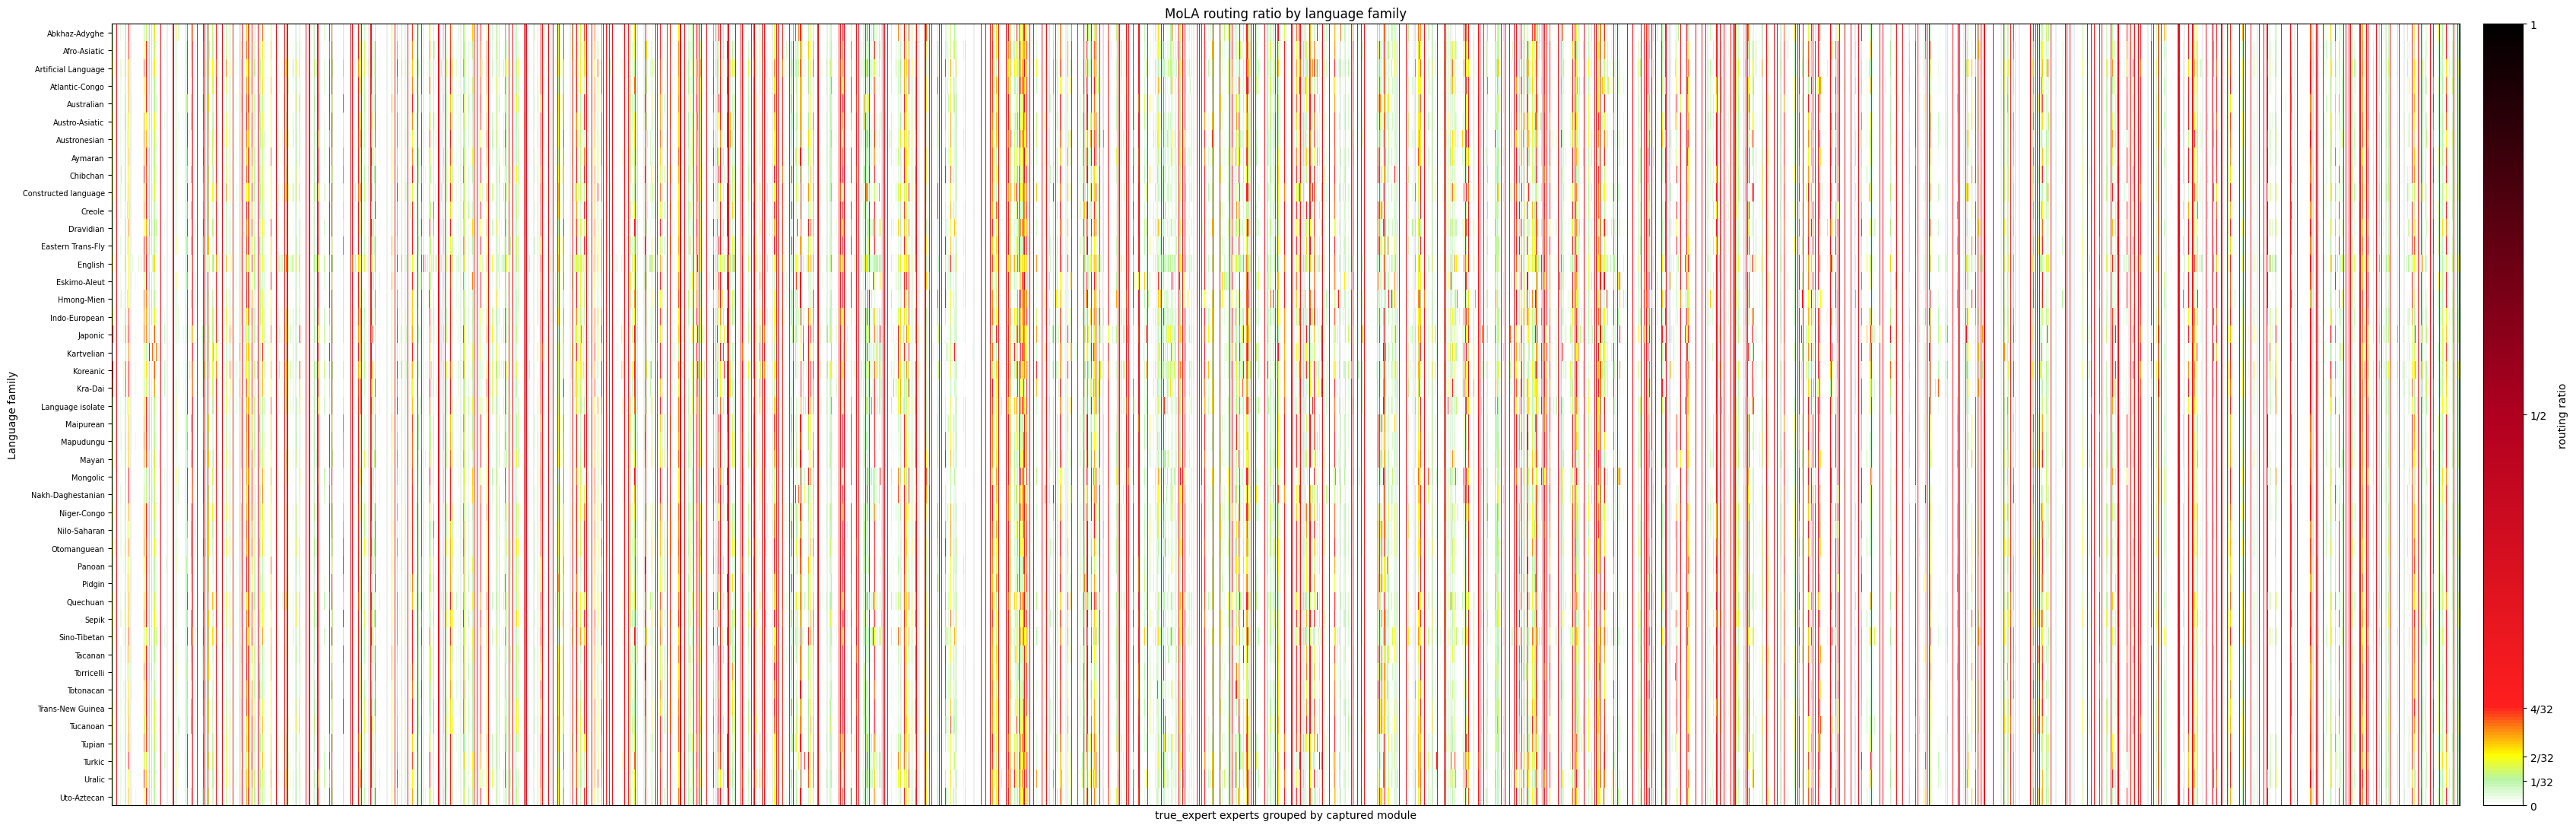

wrote /local/joeldag/repos/moe-study/outputs/routing_analysis/moe_study_final_winners_96_langs_initial_1000seq/notebook_figures/mola_tr64_e32_k4/family_lola_routing_heatmap.png


In [2]:
data = np.clip(np.nan_to_num(group_route.reshape(group_route.shape[0], -1)), 0, 1)
uniform = 1.0 / group_route.shape[2]
cmap = LinearSegmentedColormap.from_list(
    "lola_ratio",
    [(0.0, "#ffffff"), (min(uniform, 1.0), "#b8f5a5"), (min(2*uniform, 1.0), "#ffff00"),
     (min(4*uniform, 1.0), "#ff1f1f"), (0.5, "#b00020"), (1.0, "#000000")],
)
fig_w = max(12, min(34, data.shape[1] * 0.035))
fig_h = max(5, min(20, len(labels) * 0.25))
fig, ax = plt.subplots(figsize=(fig_w, fig_h))
im = ax.imshow(data, aspect="auto", interpolation="nearest", cmap=cmap, vmin=0, vmax=1)
ax.set_title(f"{APPROACH_NAME} routing ratio by language family")
ax.set_xlabel(f"{axis_name} experts grouped by captured module")
ax.set_ylabel("Language family")
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels, fontsize=7)
for boundary in range(group_route.shape[2], data.shape[1], group_route.shape[2]):
    ax.axvline(boundary - 0.5, color="black", alpha=0.25, linewidth=0.35)
ax.set_xticks([])
cb = fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01)
cb.set_label("routing ratio")
cb.set_ticks([0, uniform, min(2*uniform, 1), min(4*uniform, 1), 0.5, 1.0])
cb.set_ticklabels(["0", f"1/{group_route.shape[2]}", f"2/{group_route.shape[2]}", f"4/{group_route.shape[2]}", "1/2", "1"])
fig.tight_layout()
heatmap_path = out_dir / "family_lola_routing_heatmap.png"
fig.savefig(heatmap_path, dpi=180)
plt.show()
print("wrote", heatmap_path)


## t-SNE of family routing vectors

For each family, routing is module-normalized, flattened, L2-normalized, and embedded with cosine t-SNE. If scikit-learn is unavailable, the notebook falls back to PCA/SVD.


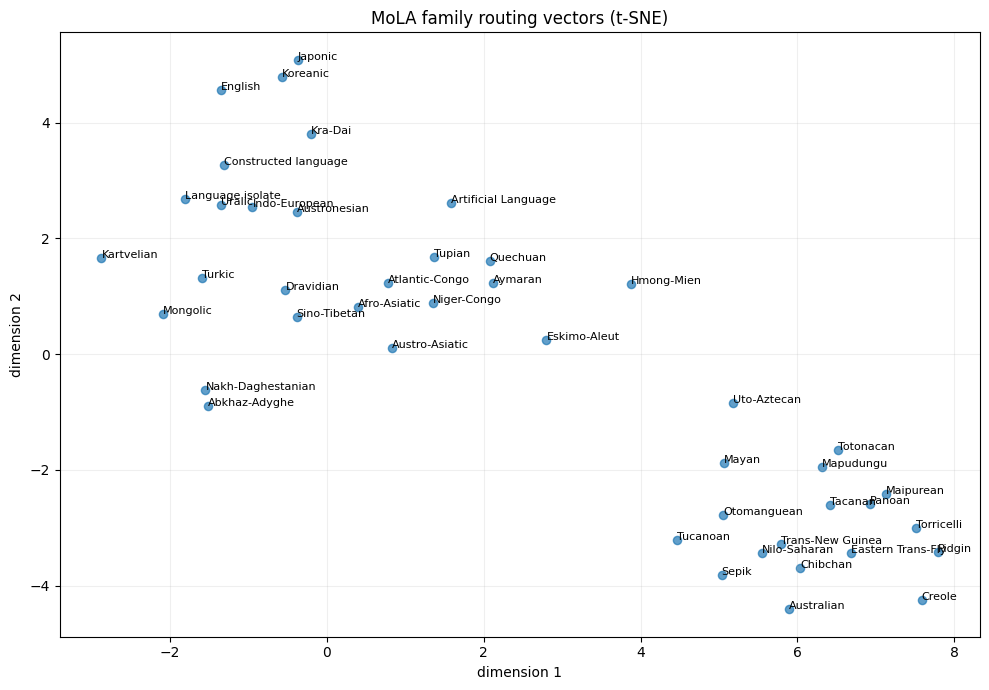

wrote /local/joeldag/repos/moe-study/outputs/routing_analysis/moe_study_final_winners_96_langs_initial_1000seq/notebook_figures/mola_tr64_e32_k4/family_routing_tsne.png


In [3]:
def normalize_rows(x):
    denom = np.linalg.norm(x, axis=1, keepdims=True)
    return np.divide(x, denom, out=np.zeros_like(x), where=denom > 0)

vectors = group_route.copy()
module_norm = np.linalg.norm(vectors, axis=2, keepdims=True)
vectors = np.divide(vectors, module_norm, out=np.zeros_like(vectors), where=module_norm > 0).reshape(len(labels), -1)
vectors = normalize_rows(vectors)
try:
    from sklearn.manifold import TSNE
    perplexity = max(2, min(30, (len(labels) - 1) // 3))
    emb = TSNE(n_components=2, metric="cosine", init="pca", learning_rate="auto", perplexity=perplexity, random_state=42).fit_transform(vectors)
    method = "t-SNE"
except Exception:
    centered = vectors - vectors.mean(axis=0, keepdims=True)
    _, _, vt = np.linalg.svd(centered, full_matrices=False)
    emb = centered @ vt[:2].T
    method = "PCA/SVD fallback"

fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(emb[:, 0], emb[:, 1], s=35, alpha=0.7)
for i, label in enumerate(labels):
    ax.text(emb[i, 0], emb[i, 1], label, fontsize=8)
ax.set_title(f"{APPROACH_NAME} family routing vectors ({method})")
ax.set_xlabel("dimension 1")
ax.set_ylabel("dimension 2")
ax.grid(alpha=0.2)
fig.tight_layout()
tsne_path = out_dir / "family_routing_tsne.png"
fig.savefig(tsne_path, dpi=180)
plt.show()
print("wrote", tsne_path)
